**Nomes:** Patrícia da Silva Costa & Valdir de Souza Carvalho Neto 

**Turma:** SI 241

# Leitura, limpeza, renomeação e separação (features e alvo, assim como dados de treino e teste)

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

caminho = "/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv"
sms_dataset = (pd.read_csv(caminho, encoding='latin-1')
               .drop(columns=['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'])
               .rename(columns={'v1': 'alvo', 'v2': 'texto'}))

sms_dataset['alvo'] = sms_dataset['alvo'].map({'ham': 0, 'spam': 1})

X = sms_dataset.texto
y = sms_dataset.alvo

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, random_state=42, stratify=y)

# Criação e aplicação da vetorização nos dados de treino e teste

### O que é TF-IDF e decisões de limpeza de texto

**1. O que é TF-IDF e como transforma as mensagens:**
Redes neurais artificiais operam apenas com entradas numéricas, sendo necessário converter os textos das mensagens em vetores de números. O **TF-IDF** (*Term Frequency - Inverse Document Frequency*) é uma técnica estatística que transforma o texto em uma matriz numérica avaliando a relevância de cada palavra dentro do conjunto de dados:
* **TF (*Term Frequency* / Frequência do Termo):** Mede a frequência com que uma palavra aparece em uma mensagem específica.
* **IDF (*Inverse Document Frequency* / Frequência Inversa nos Documentos):** Penaliza palavras que aparecem em quase todas as mensagens do conjunto de dados (que possuem baixo poder de distinção) e atribui um peso maior a palavras mais raras e específicas (como termos típicos de promoções ou golpes em mensagens de *spam*).

**2. Decisões tomadas para a limpeza do texto:**
Para realizar uma limpeza simples, padronizada e evitar vazamento de dados (*data leakage*), utilizamos os recursos nativos do próprio `TfidfVectorizer`:
* **Remoção de *Stop Words* (`stop_words='english'`):** Removemos palavras muito comuns do idioma inglês (artigos, preposições e pronomes como *"the"*, *"is"*, *"and"*, *"to"*), pois elas aparecem tanto em mensagens legítimas (*ham*) quanto em *spam* e apenas adicionariam ruído e dimensionalidade desnecessária à rede.
* **Padronização para minúsculas e tokenização (padrão do `TfidfVectorizer`):** Por padrão (`lowercase=True`), o vetorizador converte todas as letras para minúsculas (fazendo com que *"Free"* e *"free"* sejam contabilizadas como a mesma palavra) e descarta sinais de pontuação e caracteres isolados de apenas uma letra.
* **Ajuste exclusivo no treino:** O vocabulário e os pesos do TF-IDF foram aprendidos exclusivamente sobre os dados de treino (`fit_transform(X_train)`) e apenas aplicados aos dados de teste (`transform(X_test)`), garantindo uma avaliação justa.

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer

vetorizador = TfidfVectorizer(stop_words='english')

X_train_transformed = vetorizador.fit_transform(X_train)

X_test_transformed = vetorizador.transform(X_test)

print("Treino convertido:", X_train_transformed.shape)
print("Teste convertido:", X_test_transformed.shape)

Treino convertido: (3900, 6946)
Teste convertido: (1672, 6946)


# Criação de uma lista com os três modelos de Rede Neural

In [3]:
from sklearn.neural_network import MLPClassifier

modelos = [
    MLPClassifier(
        hidden_layer_sizes=(8,),
        activation="relu",
        learning_rate_init=0.05,
        max_iter=1000,
        early_stopping=True,
        random_state=42
    ),
    MLPClassifier(
        hidden_layer_sizes=(16, 8),
        activation="relu",
        learning_rate_init=0.05,
        max_iter=1000,
        early_stopping=True,
        random_state=42
    ),
    MLPClassifier(
        hidden_layer_sizes=(16, 16, 16),
        activation="relu",
        learning_rate_init=0.05,
        max_iter=1000,
        early_stopping=True,
        random_state=42
    )
]

# Treino dos três modelos, previsão na base de testes e métricas simples

In [4]:
from sklearn.metrics import accuracy_score, f1_score

for modelo in modelos:
    print(f"--> Treinando a rede com arquitetura: {modelo.hidden_layer_sizes}")
    
    modelo.fit(X_train_transformed, y_train)
    preds_train = modelo.predict(X_train_transformed)
    
    acc = accuracy_score(y_train, preds_train)
    f1 = f1_score(y_train, preds_train, pos_label=1)
    
    print(f"-> Acurácia no Treino: {acc:.4f} | F1-Score no Treino: {f1:.4f}")
    print("-" * 50)

--> Treinando a rede com arquitetura: (8,)
-> Acurácia no Treino: 0.9954 | F1-Score no Treino: 0.9825
--------------------------------------------------
--> Treinando a rede com arquitetura: (16, 8)
-> Acurácia no Treino: 0.9964 | F1-Score no Treino: 0.9865
--------------------------------------------------
--> Treinando a rede com arquitetura: (16, 16, 16)
-> Acurácia no Treino: 0.9985 | F1-Score no Treino: 0.9943
--------------------------------------------------


# Aplicação do melhor modelo na base de testes

-> Acurácia no Teste: 0.9803 | F1-Score no Teste: 0.9258
--------------------------------------------------


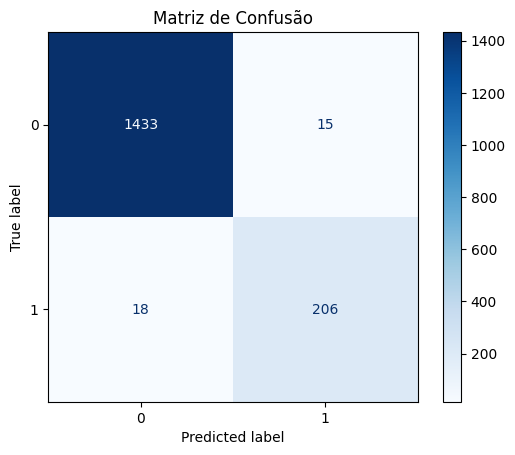

In [5]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

melhor_modelo = modelos[2]

preds_test = melhor_modelo.predict(X_test_transformed)
acc_test = accuracy_score(y_test, preds_test)
f1_test = f1_score(y_test, preds_test, pos_label=1)

print(f"-> Acurácia no Teste: {acc_test:.4f} | F1-Score no Teste: {f1_test:.4f}")
print("-" * 50)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    preds_test,
    cmap=plt.cm.Blues
)

plt.title("Matriz de Confusão")
plt.show()

### Qual rede foi melhor? Quantas mensagens legítimas foram marcadas como spam? E quantos spams passaram?

A melhor rede foi a **(16, 16, 16)**.

Um total de **15** mensagens legitimas foram marcadas como spam.

Um total de **18** spams passaram.